# Bradley–Terry with a side effect

For a between-cat pair, how much of the choice is the cat, how much is side A, and how much does not repeat.

P(choose A) = logistic(strength(cat A) − strength(cat B) + side).

Strengths are centered, so an average cat is 0. A cat missing from the fit gets 0 as well. The same equation with a strength per photo is the comparison: once on between-cat rows, once on within-cat rows. Held-out log loss decides which version is written to the test file.

Both side orders of a pair stay on the same side of a split. Predictions go to `processed/test_predictions.csv`. The file in `dataset/` is left as it is.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd()
if not (ROOT / "processed" / "train_cleaned.csv").exists():
    ROOT = ROOT.parent

FIG_DIR = ROOT / "outputs" / "figures"
OUT_DIR = ROOT / "outputs"
PROC_DIR = ROOT / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 21
N_FOLDS = 5
N_BOOT = 200
N_CAT_REPEATS = 5
C_GRID = [0.01, 0.1, 1, 10, 100]
PRIMARY_C = 1.0
rng = np.random.default_rng(SEED)

train = pd.read_csv(ROOT / "processed" / "train_cleaned.csv")
test = pd.read_csv(ROOT / "dataset" / "test.csv", encoding="utf-8-sig", dtype=str, keep_default_na=False)
between = train[train["comparison_type"] == "between_cats"].reset_index(drop=True)
within = train[train["comparison_type"] == "within_cat"].reset_index(drop=True)
print(f"between {len(between):,}   within {len(within):,}   test {len(test):,}")
print("seed", SEED)

between 21,893   within 3,003   test 6,224
seed 21


In [2]:
def logistic(x):
    return 1 / (1 + np.exp(-x))


def log_loss(y, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    y = np.asarray(y, dtype=float)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def brier(y, p):
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    return float(np.mean((p - y) ** 2))


def accuracy(y, p):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(p) >= 0.5
    return float(np.mean(pred == (y == 1)))


def fit_bt(df, id_a, id_b, C):
    ids = pd.unique(np.concatenate([df[id_a].to_numpy(), df[id_b].to_numpy()]))
    index = {item: k for k, item in enumerate(ids)}
    n = len(df)
    X = np.zeros((n, len(ids) + 1))
    rows = np.arange(n)
    a = df[id_a].map(index).to_numpy()
    b = df[id_b].map(index).to_numpy()
    X[rows, a] += 1
    X[rows, b] -= 1
    X[:, -1] = 1
    clf = LogisticRegression(
        C=C,
        fit_intercept=False,
        solver="lbfgs",
        max_iter=500,
    )
    clf.fit(X, df["chose_a"].to_numpy())
    if int(clf.n_iter_[0]) >= 500:
        raise RuntimeError(f"Bradley-Terry fit did not converge at C={C}")
    coef = clf.coef_.ravel()
    strength = coef[:-1]
    strength = strength - strength.mean()
    return {
        "strength": dict(zip(ids, strength)),
        "delta": float(coef[-1]),
        "ids": ids,
    }


def predict_bt(model, df, id_a, id_b):
    strength = model["strength"]
    sa = df[id_a].map(strength).fillna(0).to_numpy(dtype=float)
    sb = df[id_b].map(strength).fillna(0).to_numpy(dtype=float)
    return logistic(sa - sb + model["delta"])


def pair_masks(df, k, generator):
    pairs = generator.permutation(df["unordered_pair_id"].drop_duplicates().to_numpy())
    masks = []
    for fold in np.array_split(pairs, k):
        masks.append(df["unordered_pair_id"].isin(set(fold)).to_numpy())
    return masks


def heldout_predictions(df, id_a, id_b, C, masks):
    probability = np.empty(len(df))
    baseline = np.empty(len(df))
    deltas = []
    for mask in masks:
        fit_df = df.loc[~mask]
        model = fit_bt(fit_df, id_a, id_b, C)
        probability[mask] = predict_bt(model, df.loc[mask], id_a, id_b)
        baseline[mask] = fit_df["chose_a"].mean()
        deltas.append(model["delta"])
    return probability, baseline, float(np.mean(deltas))

## Full between-cat fit

The side coefficient is the log-odds of choosing A when the two cats have the same strength. `C = 1`. The path below checks that nearby penalties land on about the same held-out score.

,value
cats,237.000
side_log_odds,0.088
p_choose_A_if_equal,0.522
sd_strength,0.548
sd_strength_gap,0.668
share_gap_exceeds_side,0.878


,appearances,wins,strength
cat,,,
cat_000024,201,150,1.427
cat_001013,175,130,1.315
cat_000013,195,141,1.240
cat_000406,213,153,1.219
cat_000005,191,133,1.098


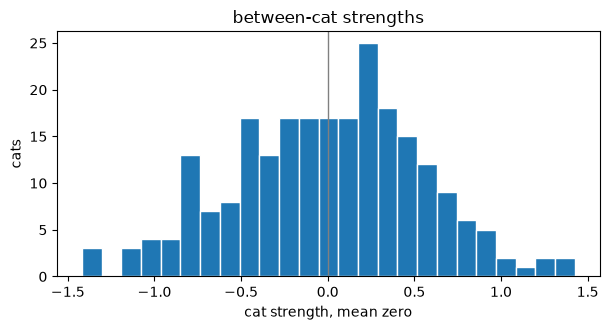

In [3]:
cat_model = fit_bt(between, "a_cat", "b_cat", PRIMARY_C)
sa = between["a_cat"].map(cat_model["strength"]).to_numpy()
sb = between["b_cat"].map(cat_model["strength"]).to_numpy()
gap = sa - sb
delta = cat_model["delta"]
equal_prob = float(logistic(delta))

strength_table = (
    pd.concat(
        [
            pd.DataFrame({"cat": between["a_cat"], "won": between["chose_a"], "side": "A"}),
            pd.DataFrame({"cat": between["b_cat"], "won": 1 - between["chose_a"], "side": "B"}),
        ]
    )
    .groupby("cat")
    .agg(appearances=("won", "size"), wins=("won", "sum"))
)
strength_table["strength"] = strength_table.index.map(cat_model["strength"])
strength_table = strength_table.sort_values("strength", ascending=False)
strength_table.to_csv(PROC_DIR / "cat_strengths.csv")

fit_summary = pd.Series(
    {
        "cats": len(cat_model["ids"]),
        "side_log_odds": delta,
        "p_choose_A_if_equal": equal_prob,
        "sd_strength": float(np.std(list(cat_model["strength"].values()), ddof=1)),
        "sd_strength_gap": float(gap.std(ddof=1)),
        "share_gap_exceeds_side": float(np.mean(np.abs(gap) > abs(delta))),
    }
)
display(fit_summary.to_frame("value").round(3))
display(strength_table.head(5).round(3))

fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.hist(strength_table["strength"], bins=25, color="C0", edgecolor="white")
ax.axvline(0, color="0.5", lw=1)
ax.set_xlabel("cat strength, mean zero")
ax.set_ylabel("cats")
ax.set_title("between-cat strengths")
fig.tight_layout()
fig.savefig(FIG_DIR / "cat_strengths.png", bbox_inches="tight")
plt.show()

## Held-out pairs

Five folds. Both orders of a pair stay in one fold. The baseline is the side rate on the rows used to fit, with no cat strength and no photo strength. Log loss is the score. Accuracy is easy to over-read, because always guessing A already lands on the side rate.

,model,C,log_loss,baseline_log_loss,brier,baseline_brier,accuracy,baseline_accuracy,mean_side
0,"between, cat",0.01,0.6776,0.6924,0.2423,0.2496,0.5947,0.5197,0.0774
1,"between, cat",0.10,0.6569,0.6924,0.2325,0.2496,0.6059,0.5197,0.0838
2,"between, cat",1.00,0.6552,0.6924,0.2316,0.2496,0.6075,0.5197,0.0878
3,"between, cat",10.00,0.6555,0.6924,0.2317,0.2496,0.6072,0.5197,0.0885
4,"between, cat",100.00,0.6556,0.6924,0.2317,0.2496,0.6075,0.5197,0.0886
5,"between, image",0.01,0.6875,0.6924,0.2472,0.2496,0.5408,0.5197,0.0772
6,"between, image",0.10,0.6685,0.6924,0.2379,0.2496,0.5944,0.5197,0.0817
7,"between, image",1.00,0.6675,0.6924,0.2367,0.2496,0.6030,0.5197,0.0913
8,"between, image",10.00,0.6844,0.6924,0.2418,0.2496,0.6043,0.5197,0.0966
9,"between, image",100.00,0.6898,0.6924,0.2432,0.2496,0.6049,0.5197,0.0975


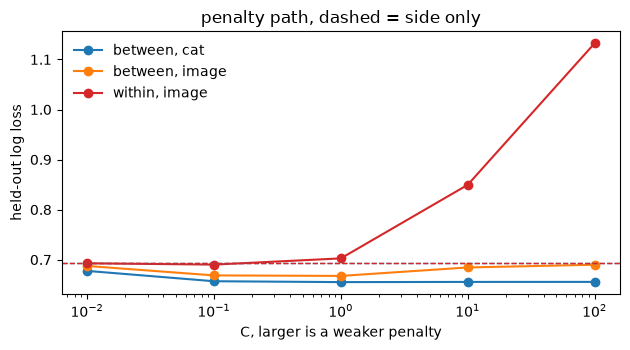

In [4]:
between_masks = pair_masks(between, N_FOLDS, rng)
within_masks = pair_masks(within, N_FOLDS, rng)

path_specs = [
    ("between, cat", between, "a_cat", "b_cat", between_masks),
    ("between, image", between, "a_image", "b_image", between_masks),
    ("within, image", within, "a_image", "b_image", within_masks),
]
path_rows = []
for label, data, id_a, id_b, masks in path_specs:
    for C in C_GRID:
        probability, baseline, mean_delta = heldout_predictions(data, id_a, id_b, C, masks)
        y = data["chose_a"].to_numpy()
        path_rows.append(
            {
                "model": label,
                "C": C,
                "log_loss": log_loss(y, probability),
                "baseline_log_loss": log_loss(y, baseline),
                "brier": brier(y, probability),
                "baseline_brier": brier(y, baseline),
                "accuracy": accuracy(y, probability),
                "baseline_accuracy": accuracy(y, baseline),
                "mean_side": mean_delta,
            }
        )
path = pd.DataFrame(path_rows)
path.to_csv(OUT_DIR / "regularization_path.csv", index=False)
display(path.round(4))

fig, ax = plt.subplots(figsize=(6.4, 3.6))
for label, color in [
    ("between, cat", "C0"),
    ("between, image", "C1"),
    ("within, image", "C3"),
]:
    part = path[path["model"] == label]
    ax.plot(part["C"], part["log_loss"], marker="o", color=color, label=label)
base_between = path.loc[path["model"] == "between, cat", "baseline_log_loss"].iloc[0]
base_within = path.loc[path["model"] == "within, image", "baseline_log_loss"].iloc[0]
ax.axhline(base_between, color="C0", lw=1, ls="--")
ax.axhline(base_within, color="C3", lw=1, ls="--")
ax.set_xscale("log")
ax.set_xlabel("C, larger is a weaker penalty")
ax.set_ylabel("held-out log loss")
ax.set_title("penalty path, dashed = side only")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "regularization_path.png", bbox_inches="tight")
plt.show()

## Main comparison

Between-cat models at `C = 1`, on the flat part of the cat path. The within-cat photo model is shown at `C = 1` and at `C = 0.1`, which is the best within-cat loss on the grid. Within-cat test rows get the side rate. Neither photo model beats that rate by enough to justify a strength per photo.

,log_loss,brier,accuracy
model,,,
"between, side only",0.6924,0.2496,0.5197
"between, cat + side",0.6552,0.2316,0.6075
"between, image + side",0.6675,0.2367,0.6030
"within, side only",0.6933,0.2501,0.5142
"within, image + side, C=1",0.7025,0.2538,0.5431
"within, image + side, C=0.1",0.6901,0.2485,0.5355


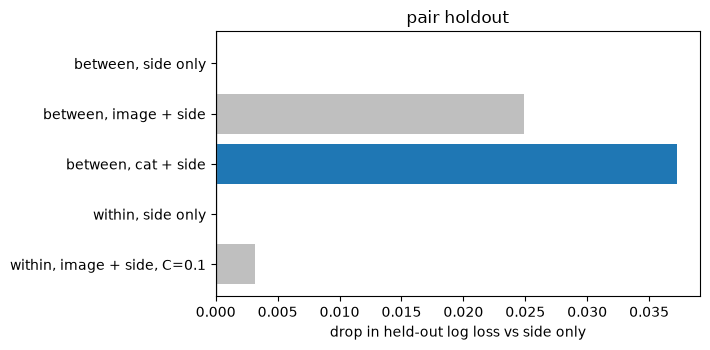

In [5]:
primary_specs = [
    ("between, side only", None),
    ("between, cat + side", ("between, cat", PRIMARY_C)),
    ("between, image + side", ("between, image", PRIMARY_C)),
    ("within, side only", None),
    ("within, image + side, C=1", ("within, image", 1.0)),
    ("within, image + side, C=0.1", ("within, image", 0.1)),
]
primary_rows = []
for label, key in primary_specs:
    if key is None:
        model_name = "between, cat" if label.startswith("between") else "within, image"
        row = path[path["model"] == model_name].iloc[0]
        primary_rows.append(
            {
                "model": label,
                "log_loss": row["baseline_log_loss"],
                "brier": row["baseline_brier"],
                "accuracy": row["baseline_accuracy"],
            }
        )
    else:
        row = path[(path["model"] == key[0]) & (path["C"] == key[1])].iloc[0]
        primary_rows.append(
            {
                "model": label,
                "log_loss": row["log_loss"],
                "brier": row["brier"],
                "accuracy": row["accuracy"],
            }
        )
primary = pd.DataFrame(primary_rows).set_index("model")
primary.to_csv(OUT_DIR / "pair_holdout_logloss.csv")
display(primary.round(4))

baseline_for = {
    "between, side only": "between, side only",
    "between, image + side": "between, side only",
    "between, cat + side": "between, side only",
    "within, side only": "within, side only",
    "within, image + side, C=0.1": "within, side only",
}
gain = pd.Series(
    {
        name: primary.loc[base, "log_loss"] - primary.loc[name, "log_loss"]
        for name, base in baseline_for.items()
    }
)
gain = gain.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.2, 3.6))
colors = ["C0" if "cat + side" in name else "0.75" for name in gain.index]
ax.barh(gain.index, gain.to_numpy(), color=colors)
ax.axvline(0, color="0.5", lw=1)
ax.set_xlabel("drop in held-out log loss vs side only")
ax.set_title("pair holdout")
fig.tight_layout()
fig.savefig(FIG_DIR / "pair_holdout_logloss.png", bbox_inches="tight")
plt.show()

## Cats left out of the fit

Each repeat drops a quarter of the cats. Among pairs of the cats that remain, a fifth of the pairs are held out as well, so the both-seen score is on pairs the fit did not use. An unseen cat has strength 0.

,mean_n,log_loss,log_loss_sd,baseline_log_loss,gain,gain_sd
slice,,,,,,
"both seen, new pair",2467.4,0.6621,0.0073,0.6919,0.0298,0.0070
one unseen cat,8250.4,0.6854,0.0043,0.6925,0.0071,0.0041
two unseen cats,1321.6,0.6936,0.0013,0.6935,-0.0001,0.0001


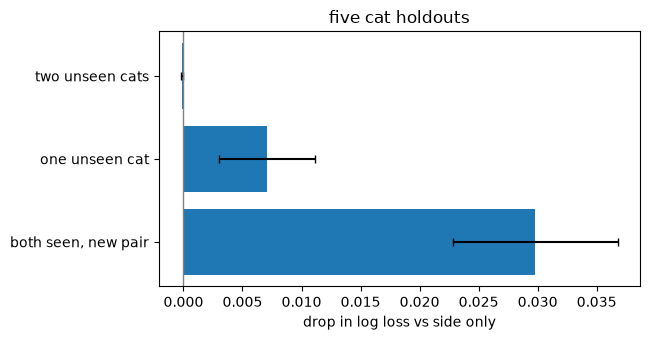

In [6]:
slice_rows = []
for repeat in range(N_CAT_REPEATS):
    cats = np.unique(np.concatenate([between["a_cat"].to_numpy(), between["b_cat"].to_numpy()]))
    held_cats = set(rng.permutation(cats)[: len(cats) // 4])
    seen_pair = ~between["a_cat"].isin(held_cats) & ~between["b_cat"].isin(held_cats)
    seen_ids = between.loc[seen_pair, "unordered_pair_id"].drop_duplicates().to_numpy()
    n_hold = max(1, int(round(len(seen_ids) * 0.2)))
    held_pairs = set(rng.permutation(seen_ids)[:n_hold])
    fit_mask = seen_pair & ~between["unordered_pair_id"].isin(held_pairs)
    model = fit_bt(between.loc[fit_mask], "a_cat", "b_cat", PRIMARY_C)
    probability = predict_bt(model, between, "a_cat", "b_cat")
    base = float(between.loc[fit_mask, "chose_a"].mean())
    n_unseen = between["a_cat"].isin(held_cats).astype(int) + between["b_cat"].isin(held_cats).astype(int)
    slices = {
        "both seen, new pair": between["unordered_pair_id"].isin(held_pairs).to_numpy(),
        "one unseen cat": (n_unseen == 1).to_numpy(),
        "two unseen cats": (n_unseen == 2).to_numpy(),
    }
    for name, mask in slices.items():
        y = between.loc[mask, "chose_a"].to_numpy()
        slice_rows.append(
            {
                "repeat": repeat,
                "slice": name,
                "n": int(mask.sum()),
                "log_loss": log_loss(y, probability[mask]),
                "baseline_log_loss": log_loss(y, np.full(mask.sum(), base)),
            }
        )

slices_long = pd.DataFrame(slice_rows)
slices_long["gain"] = slices_long["baseline_log_loss"] - slices_long["log_loss"]
slice_summary = (
    slices_long.groupby("slice")
    .agg(
        mean_n=("n", "mean"),
        log_loss=("log_loss", "mean"),
        log_loss_sd=("log_loss", "std"),
        baseline_log_loss=("baseline_log_loss", "mean"),
        gain=("gain", "mean"),
        gain_sd=("gain", "std"),
    )
    .reindex(["both seen, new pair", "one unseen cat", "two unseen cats"])
)
slice_summary.to_csv(OUT_DIR / "cat_holdout_logloss.csv")
display(slice_summary.round(4))

fig, ax = plt.subplots(figsize=(6.6, 3.5))
ypos = np.arange(len(slice_summary))
ax.barh(
    ypos,
    slice_summary["gain"],
    color="C0",
    xerr=slice_summary["gain_sd"],
    capsize=3,
)
ax.axvline(0, color="0.5", lw=1)
ax.set_yticks(ypos, slice_summary.index)
ax.set_xlabel("drop in log loss vs side only")
ax.set_title("five cat holdouts")
fig.tight_layout()
fig.savefig(FIG_DIR / "cat_holdout_slices.png", bbox_inches="tight")
plt.show()

## Interval for the side effect

200 draws. Each draw resamples unordered pairs with replacement and refits the between-cat model at `C = 1`. The interval is the 2.5 and 97.5 percentiles of the side coefficient.

In [7]:
groups = [index.to_numpy() for index in between.groupby("unordered_pair_id").groups.values()]
boot_delta = np.empty(N_BOOT)
for draw in range(N_BOOT):
    chosen = rng.integers(0, len(groups), size=len(groups))
    sample_index = np.concatenate([groups[i] for i in chosen])
    boot_delta[draw] = fit_bt(between.iloc[sample_index], "a_cat", "b_cat", PRIMARY_C)["delta"]

boot_low, boot_high = np.quantile(boot_delta, [0.025, 0.975])
boot_summary = pd.Series(
    {
        "draws": N_BOOT,
        "side_log_odds": delta,
        "boot_mean": float(boot_delta.mean()),
        "boot_low_95": float(boot_low),
        "boot_high_95": float(boot_high),
        "p_equal": equal_prob,
        "p_equal_low": float(logistic(boot_low)),
        "p_equal_high": float(logistic(boot_high)),
    }
)
boot_summary.to_csv(OUT_DIR / "side_effect_bootstrap.csv", header=["value"])
display(boot_summary.to_frame("value").round(4))
print(f"P(A | equal cats) = {equal_prob:.3f}")
print(f"pair bootstrap 95% {logistic(boot_low):.3f} to {logistic(boot_high):.3f}")

,value
draws,200.0000
side_log_odds,0.0879
boot_mean,0.0883
boot_low_95,0.0646
boot_high_95,0.1156
p_equal,0.5220
p_equal_low,0.5161
p_equal_high,0.5289


P(A | equal cats) = 0.522
pair bootstrap 95% 0.516 to 0.529


## Test predictions

Between-cat rows use the full-data cat strengths and the side effect. A cat that never appears in training has strength 0. Within-cat rows use the within-cat rate of choosing A. `choice` is A when `prob_a` is at least 0.5.

In [8]:
train_cats = set(cat_model["ids"])
train_images = set(train["a_image"]) | set(train["b_image"])
within_rate = float(within["chose_a"].mean())

predictions = test.copy()
is_between = predictions["comparison_type"].eq("between_cats").to_numpy()
prob = np.empty(len(predictions))
prob[is_between] = predict_bt(cat_model, predictions.loc[is_between], "a_cat", "b_cat")
prob[~is_between] = within_rate
predictions["prob_a"] = prob
predictions["choice"] = np.where(predictions["prob_a"] >= 0.5, "A", "B")

new_cats = (~predictions["a_cat"].isin(train_cats)).astype(int) + (~predictions["b_cat"].isin(train_cats)).astype(int)
predictions["_slice"] = np.where(
    ~is_between,
    "within_cat",
    np.where(new_cats == 0, "both cats seen", np.where(new_cats == 1, "one unseen cat", "two unseen cats")),
)
slice_pred = (
    predictions.groupby("_slice")
    .agg(
        rows=("prob_a", "size"),
        mean_prob_a=("prob_a", "mean"),
        min_prob_a=("prob_a", "min"),
        max_prob_a=("prob_a", "max"),
        share_choice_A=("choice", lambda s: np.mean(s == "A")),
    )
    .reindex(["both cats seen", "one unseen cat", "two unseen cats", "within_cat"])
)
display(slice_pred.round(3))

out_cols = list(test.columns)
submission = predictions[out_cols]
submission.to_csv(PROC_DIR / "test_predictions.csv", index=False)
print("wrote processed/test_predictions.csv", len(submission), "rows")
print(submission["choice"].value_counts().to_dict())
missing_photo = (
    ~predictions.loc[~is_between, "a_image"].isin(train_images)
    | ~predictions.loc[~is_between, "b_image"].isin(train_images)
)
print("within-cat test rows with a photo absent from training:", int(missing_photo.sum()), "of", int((~is_between).sum()))

,rows,mean_prob_a,min_prob_a,max_prob_a,share_choice_A
_slice,,,,,
both cats seen,2743,0.523,0.061,0.948,0.565
one unseen cat,1556,0.520,0.209,0.819,0.542
two unseen cats,926,0.522,0.522,0.522,1.000
within_cat,999,0.514,0.514,0.514,1.000


wrote processed/test_predictions.csv 6224 rows
{'A': 4317, 'B': 1907}
within-cat test rows with a photo absent from training: 630 of 999


## What the holdouts say

Cat strength lowers the between-cat held-out log loss. Photo strength lowers it by less. On within-cat rows the photo model at `C = 1` is worse than the side rate, and at `C = 0.1` the gain is small. The gain from cat strength shrinks when one cat is new and is gone when both cats are new.

In [9]:
cat_loss = primary.loc["between, cat + side", "log_loss"]
side_loss = primary.loc["between, side only", "log_loss"]
image_loss = primary.loc["between, image + side", "log_loss"]
within_side = primary.loc["within, side only", "log_loss"]
within_image = primary.loc["within, image + side, C=0.1", "log_loss"]
print(f"side log-odds {delta:.3f}")
print(f"P(A | equal cats) {equal_prob:.3f}   bootstrap {logistic(boot_low):.3f} to {logistic(boot_high):.3f}")
print(f"sd of cat-strength gap {gap.std(ddof=1):.3f}")
print(f"share of rows with |gap| > |side| {np.mean(np.abs(gap) > abs(delta)):.3f}")
print(f"pair-holdout log loss   side {side_loss:.4f}   image {image_loss:.4f}   cat {cat_loss:.4f}")
print(f"within-cat log loss   side {within_side:.4f}   best image model {within_image:.4f}")
for name, row in slice_summary.iterrows():
    print(
        f"{name}: {row.log_loss:.4f} (sd {row.log_loss_sd:.4f}) vs side {row.baseline_log_loss:.4f}, mean n {row.mean_n:.0f}"
    )
print("test mean prob_a")
for idx, row in slice_pred.iterrows():
    print(f"  {idx} {row.mean_prob_a:.3f}")

side log-odds 0.088
P(A | equal cats) 0.522   bootstrap 0.516 to 0.529
sd of cat-strength gap 0.668
share of rows with |gap| > |side| 0.878
pair-holdout log loss   side 0.6924   image 0.6675   cat 0.6552
within-cat log loss   side 0.6933   best image model 0.6901
both seen, new pair: 0.6621 (sd 0.0073) vs side 0.6919, mean n 2467
one unseen cat: 0.6854 (sd 0.0043) vs side 0.6925, mean n 8250
two unseen cats: 0.6936 (sd 0.0013) vs side 0.6935, mean n 1322
test mean prob_a
  both cats seen 0.523
  one unseen cat 0.520
  two unseen cats 0.522
  within_cat 0.514
